# Assignment 1 — Data Exploration and Cleaning: Follows

Each row represents a directed edge: follower → followed. We examine structure, missing values, duplicates, consistency, outliers, and opportunities for integration and derived information.

Requirements: Python 3.10+, pandas 2.0+, NumPy, and Matplotlib. Adjust the paths below and run cells in order. Original files remain unchanged. `EXPORT = True` writes compressed CSVs; it is off by default to avoid creating large data copies.


In [1]:
from pathlib import Path
from urllib.parse import urlsplit
import xml.etree.ElementTree as ET
import json
import re
import html
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = Path(r"C:\Users\bucco\Desktop\Laboratory of Data Science\project")
DATA_DIR = PROJECT_DIR / "Truth-Social-Analysis-and-Data-Warehousing---Decision-Support-Systems-" / "Project_Data"
EXPORT = False


## 1. Load the network with bounded memory

This column-oriented JSON contains roughly four million edges. The additional lightweight dependency `ijson` reads one column at a time; the row keys are checked before aligning columns. This avoids the large temporary dictionaries created by a full JSON load.


In [2]:
import ijson
edge_columns = {}
for col in ["follower", "followed"]:
    values = []
    with (DATA_DIR / "follows.json").open("rb") as file:
        for position, (key, value) in enumerate(ijson.kvitems(file, col)):
            assert key == str(position), "Unexpected row ordering: align JSON row keys before continuing."
            values.append(value)
    edge_columns[col] = pd.Series(values, dtype="Int64")
assert len(edge_columns["follower"]) == len(edge_columns["followed"])
df_raw = pd.DataFrame(edge_columns)
del values, edge_columns
print("Rows and columns:", df_raw.shape)
display(df_raw.head())
display(df_raw.isna().sum().to_frame("Missing IDs"))
assert df_raw.notna().all().all() and df_raw.gt(0).all().all()


Rows and columns: (4002115, 2)


,follower,followed
0,12475,22025
1,12475,22026
2,12475,22027
3,12475,22028
4,12475,17280


,Missing IDs
follower,0
followed,0


In [3]:
removed_duplicates = int(df_raw.duplicated().sum())
df_clean = df_raw.drop_duplicates().reset_index(drop=True).copy()
self_follow = df_clean["follower"].eq(df_clean["followed"])
print("Duplicate directed edges removed:", removed_duplicates)
print("Self-follows retained for review:", self_follow.sum())
assert not df_clean.duplicated().any()
print("Distinct followers:", df_clean["follower"].nunique())
print("Distinct followed users:", df_clean["followed"].nunique())


Duplicate directed edges removed: 99
Self-follows retained for review: 0
Distinct followers: 2660
Distinct followed users: 444872


## 2. User coverage and missing references

Distinct IDs are never merged by username. A relationship to an absent user is kept with an integrity flag, rather than inventing a profile or silently removing an edge.


In [4]:
user_ids, profile_records = [], []
context = ET.iterparse(DATA_DIR / "users.xml", events=("start", "end"))
_, root = next(context)
for event, elem in context:
    if event == "end" and elem.tag == "row":
        user_id = int(elem.findtext("id_user"))
        user_ids.append(user_id)
        if elem.findtext("follower_count") != "-1":
            profile_records.append((user_id, int(elem.findtext("follower_count")), int(elem.findtext("following_count"))))
        root.clear()
assert len(user_ids) == len(set(user_ids))
user_ids = pd.Index(user_ids, dtype="int64")
profiles = pd.DataFrame(profile_records, columns=["id_user", "follower_count", "following_count"])
del context, root, elem, profile_records
unknown_follower = ~df_clean["follower"].isin(user_ids)
unknown_followed = ~df_clean["followed"].isin(user_ids)
unmatched = unknown_follower | unknown_followed
display(df_clean.loc[unmatched])
print("Unknown user IDs:", sorted(set(df_clean.loc[unknown_follower, "follower"]) | set(df_clean.loc[unknown_followed, "followed"])))


Unknown user IDs: [np.int64(97)]


,follower,followed
1159055,26,97


## 3. Observed degrees and statistical outliers

Network counts describe distinct non-self edges in this supplied file. A zero means no edge of that direction was observed, not that the platform count is zero. All user IDs from either source are represented in the feature table, with an explicit profile-presence indicator.


In [5]:
edges = df_clean.loc[~self_follow]
network_ids = pd.Index(pd.concat([edges["follower"], edges["followed"]]).unique())
nodes = pd.DataFrame({"id_user": user_ids.union(network_ids)})
nodes["in_users_xml"] = nodes["id_user"].isin(user_ids)
nodes["appears_in_follows"] = nodes["id_user"].isin(network_ids)
nodes["observed_follower_count"] = nodes["id_user"].map(edges["followed"].value_counts()).fillna(0).astype("Int64")
nodes["observed_following_count"] = nodes["id_user"].map(edges["follower"].value_counts()).fillna(0).astype("Int64")
assert nodes["observed_follower_count"].sum() == len(edges)
assert nodes["observed_following_count"].sum() == len(edges)
display(nodes[["observed_follower_count", "observed_following_count"]].describe(percentiles=[.5, .9, .95, .99]).round(2))
print("Users from XML with no observed edge:", (nodes["in_users_xml"] & ~nodes["appears_in_follows"]).sum())
display(nodes.nlargest(10, "observed_follower_count"))


Users from XML with no observed edge: 42342


,observed_follower_count,observed_following_count
count,487293.0,487293.0
mean,8.21,8.21
std,28.42,218.15
min,0.0,0.0
50%,1.0,0.0
90%,18.0,0.0
95%,40.0,0.0
99%,110.0,0.0
max,1842.0,29550.0


,id_user,in_users_xml,appears_in_follows,observed_follower_count,observed_following_count
5,27,True,True,1842,5
278,300,True,True,1662,228
138,160,True,True,1588,0
4,26,True,True,1552,179
189,211,True,True,1466,1
83,105,True,True,1450,258
156,178,True,True,1448,0
177,199,True,True,1397,232
300,322,True,True,1394,301
537,559,True,True,1328,4


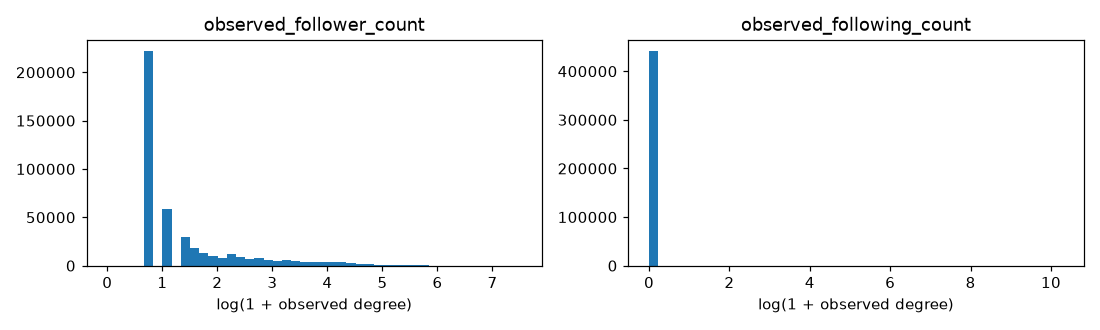

,Metric,IQR upper,Outlier nodes
0,observed_follower_count,11.0,65444
1,observed_following_count,0.0,2660


In [6]:
outliers = []
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, col in zip(axes, ["observed_follower_count", "observed_following_count"]):
    counts = nodes.loc[nodes["appears_in_follows"], col]
    q1, q3 = counts.quantile([.25, .75])
    upper = q3 + 1.5 * (q3 - q1)
    nodes[col + "_outlier"] = nodes[col].gt(upper)
    outliers.append({"Metric": col, "IQR upper": upper, "Outlier nodes": int(counts.gt(upper).sum())})
    ax.hist(np.log1p(counts.astype(float)), bins=45)
    ax.set_title(col)
    ax.set_xlabel("log(1 + observed degree)")
plt.tight_layout()
plt.show()
display(pd.DataFrame(outliers))


## 4. Reciprocity and profile comparisons

Reciprocal directed edges are counted separately; mutual pairs are half the reciprocal-edge count. This is sample reciprocity, not an estimate for the entire platform. Profile counts may come from different collection times and are not replaced with network degrees.


In [7]:
pairs = pd.MultiIndex.from_frame(edges[["follower", "followed"]])
reverse_pairs = pd.MultiIndex.from_arrays([edges["followed"], edges["follower"]])
reciprocal = pairs.isin(reverse_pairs)
print("Reciprocal directed edges:", reciprocal.sum())
print("Mutual pairs:", reciprocal.sum() // 2)
print("Sample reciprocity (%):", round(reciprocal.mean() * 100, 2))
del pairs, reverse_pairs

comparison = profiles.merge(nodes, on="id_user", how="left", validate="one_to_one")
for col in ["follower_count", "following_count"]:
    difference = comparison["observed_" + col] - comparison[col]
    print(col, {"observed_lower": int(difference.lt(0).sum()), "equal": int(difference.eq(0).sum()), "observed_higher": int(difference.gt(0).sum())})


Reciprocal directed edges: 60230
Mutual pairs: 30115
Sample reciprocity (%): 1.5
follower_count {'observed_lower': 21308, 'equal': 99, 'observed_higher': 548}
following_count {'observed_lower': 19179, 'equal': 2251, 'observed_higher': 525}


## 5. Validation and optional exports

The clean file contains the two original edge columns. Node features and relationships requiring review are separate. There is no timestamp or post text in this source; temporal activity, geography, and post-topic inference require other evidence.


In [8]:
df_final = df_clean.copy()
assert len(df_final) == len(df_raw) - removed_duplicates
assert df_final.notna().all().all() and df_final.gt(0).all().all()
assert not df_final.duplicated().any()
assert nodes["id_user"].is_unique
issues = df_final.loc[unmatched | self_follow].copy()
issues["unknown_follower"] = unknown_follower[unmatched | self_follow]
issues["unknown_followed"] = unknown_followed[unmatched | self_follow]
quality_summary = pd.Series({
    'Original rows': len(df_raw),
    'Cleaned edges': len(df_final),
    'Duplicates removed': removed_duplicates,
    'Self-follows': int(self_follow.sum()),
    'Edges with absent users': int(unmatched.sum()),
    'Observed network users': len(network_ids),
}, name="Count")
display(quality_summary.to_frame())


,Count
Original rows,4002115
Cleaned edges,4002016
Duplicates removed,99
Self-follows,0
Edges with absent users,1
Observed network users,444951


In [9]:
OUTPUT_DIR = Path.cwd() / "output_follows"
if EXPORT:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    df_final.to_csv(OUTPUT_DIR / "follows_clean.csv.gz", index=False, chunksize=50000)
    nodes.to_csv(OUTPUT_DIR / "follows_node_features.csv.gz", index=False)
    issues.to_csv(OUTPUT_DIR / "follows_issues.csv.gz", index=False)
    quality_summary.to_csv(OUTPUT_DIR / "follows_quality_summary.csv", index_label="Check")
else:
    print("Network analysis complete. Set EXPORT = True to save datasets.")


Network analysis complete. Set EXPORT = True to save datasets.


## Conclusions and Assignment 1 coverage

**Observed results:** Original rows: 4,002,115; Cleaned edges: 4,002,016; Duplicates removed: 99; Self-follows: 0; Edges with absent users: 1; Observed network users: 444,951.

Exact duplicate edges are removed. Missing users and self-follows, if present, are documented without deleting source relationships. Observed degree outliers remain: they do not establish spam or automation. Profile counts are retained as separate measurements.

The notebook covers structure and types, missing and invalid identifiers, duplicate edges, referential integrity, network coverage, degree distributions and outliers, reciprocity, user/profile integration, derived node features, and validated exports. No extra web data is necessary for these supported operations; unsupported locations or demographic attributes are not inferred. Source files are `follows.json` and `users.xml`, alongside the assignment and original Follows exploration/cleaning notebooks.
